# Tech Challenge Fase 2 — Projeto 2: Rotas de medicamentos com AG + LLM

Notebook de demonstração. Para rodar tudo do zero: `rotas experiments`, `rotas simulate-week`.
Aqui usamos os resultados já salvos em `results/` e fazemos uma otimização ao vivo, menor.

> As chamadas à LLM usam `LLM_PROVIDER` do `.env`. Para não gastar cota, o notebook exibe os textos já gerados pelo Gemini (em `results/llm/`) e faz **uma** chamada ao vivo opcional no final.

In [1]:
import json, os
from pathlib import Path
import pandas as pd
from IPython.display import Markdown, Image, display
os.chdir(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
RES = Path('results')

## 1. Cenário: São Paulo, 40 entregas, frota mista

In [2]:
from rotas.domain import Scenario
sc = Scenario.load(RES / 'scenario.json')
pd.DataFrame([{ 'id': d.id, 'destino': d.location.name, 'tipo': d.location.kind, 'prioridade': d.priority.label,
   'refrigerado': d.refrigerated, 'kg': d.demand_kg, 'janela': d.window} for d in sc.deliveries]).head(12)

,id,destino,tipo,prioridade,refrigerado,kg,janela
0,1,Paciente domiciliar #01 (Jabaquara),domiciliar,crítica,False,2.9,"(660, 840)"
1,2,Paciente domiciliar #02 (Tatuapé),domiciliar,urgente,True,4.2,"(510, 690)"
2,3,Paciente domiciliar #03 (Santo Amaro),domiciliar,regular,True,4.4,"(600, 780)"
3,4,Paciente domiciliar #04 (Freguesia do Ó),domiciliar,urgente,False,4.3,"(720, 840)"
4,5,UBS Pirituba 01,ubs,regular,False,14.9,None
5,6,UBS Capão Redondo 01,ubs,regular,False,29.9,None
6,7,UBS Tatuapé 01,ubs,urgente,False,32.2,None
7,8,Clínica de Especialidades Vila Maria 01,clinica,urgente,False,9.7,None
8,9,Hospital Dia Itaquera 01,hospital,regular,False,68.4,None
9,10,Paciente domiciliar #10 (Perdizes),domiciliar,regular,False,1.8,"(510, 690)"


In [3]:
pd.DataFrame([v.__dict__ for v in sc.vehicles])

,id,name,kind,capacity_kg,max_range_km,speed_kmh,refrigerated,cost_per_km
0,1,Van Refrigerada 1,van,400,180,22,True,1.8
1,2,Van Refrigerada 2,van,400,180,22,True,1.8
2,3,Van Carga 3,van,600,200,22,False,1.5
3,4,Moto 4,moto,25,120,32,False,0.5
4,5,Moto 5,moto,25,120,32,False,0.5


## 2. Algoritmo genético ao vivo (300 gerações, ~2 s)

In [4]:
from rotas.ga.engine import GeneticVRP, GAConfig
from rotas.evaluation import summarize
res = GeneticVRP(sc, GAConfig(generations=300, local_search=True, seed=7)).run()
summarize(sc, res.best)

{'custo_objetivo': 595.86,
 'distancia_total_km': 367.19,
 'custo_operacional_rs': 632.65,
 'viavel': True,
 'penalidade': 0.0,
 'veiculos_usados': 3,
 'entregas': 40,
 'tempo_medio_ate_criticas_h': 3.15,
 'tempo_max_ate_criticas_h': 6.72,
 'violacoes': {'overload_kg': 0.0,
  'over_range_km': 0.0,
  'refrigeration': 0,
  'late_min': 0.0,
  'overtime_min': 0.0}}

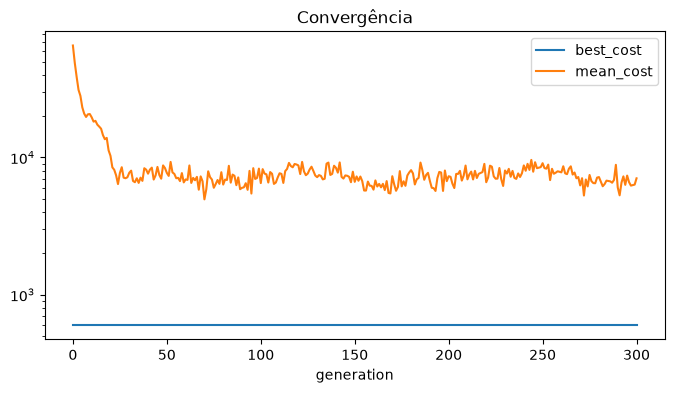

In [5]:
import matplotlib.pyplot as plt
h = pd.DataFrame([x.__dict__ for x in res.history])
ax = h.plot(x='generation', y=['best_cost', 'mean_cost'], logy=True, figsize=(8, 4), title='Convergência')
plt.show()

## 3. Experimentos (9 configurações × 5 seeds, 1500 gerações)

In [6]:
pd.read_csv(RES / 'experiments_summary.csv')

,experiment,cost_mean,cost_std,cost_best,distance_mean,feasible_rate,critical_mean_h,evaluations_mean,time_s_mean
0,E9_memetico,477.118,25.551,449.620,283.754,0.8,2.278,148114.8,21.776
1,E2_pop_50,490.779,37.227,461.289,290.829,1.0,2.440,49581.4,4.564
2,E1_base,495.753,26.545,463.806,289.917,1.0,2.444,174459.4,15.372
3,E5_cx_pmx,503.298,44.589,470.701,300.992,0.8,2.486,157536.0,16.558
4,E3_pop_300,522.491,65.246,465.220,305.243,0.8,2.548,407862.0,36.863
5,E4_mutacao_0.1,553.875,55.553,499.005,337.996,0.8,2.620,24702.8,7.216
6,E8_semente_vizinho,573.694,14.043,554.579,344.608,1.0,2.822,175119.0,16.781
7,E7_selecao_roleta,604.948,180.408,471.501,340.444,0.8,2.470,189582.2,22.060
8,E6_cx_erx,1719.408,558.243,1220.176,507.376,0.0,3.078,211924.6,51.788


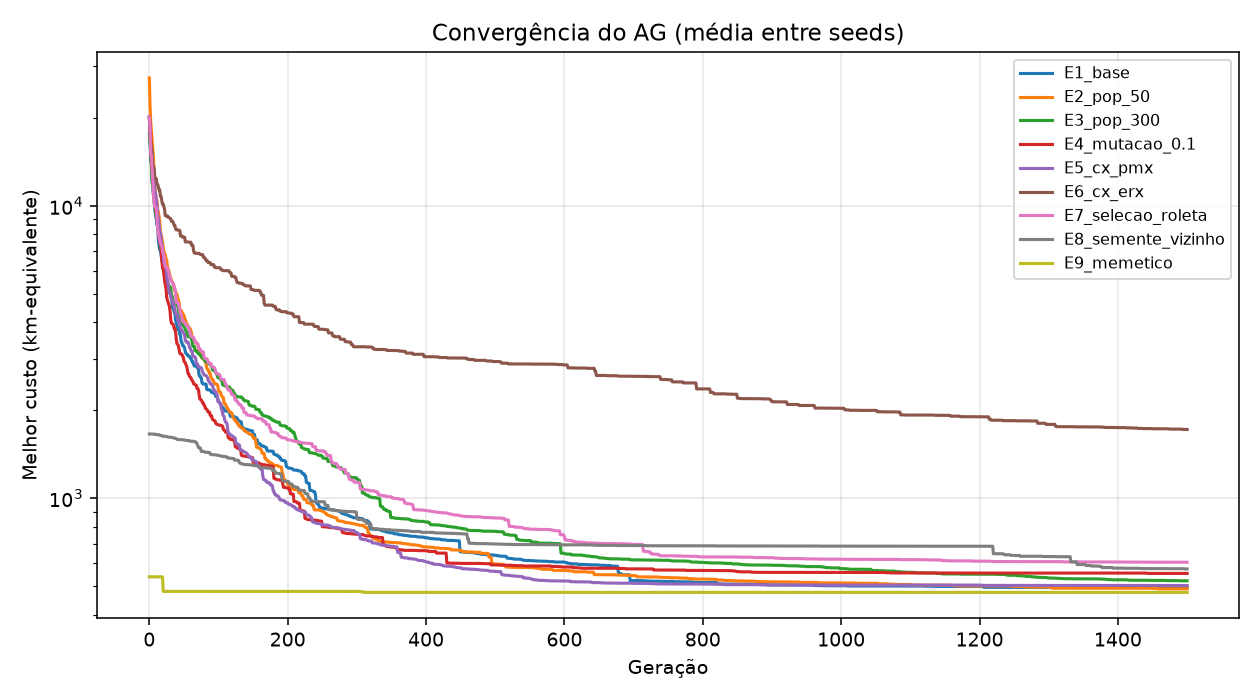

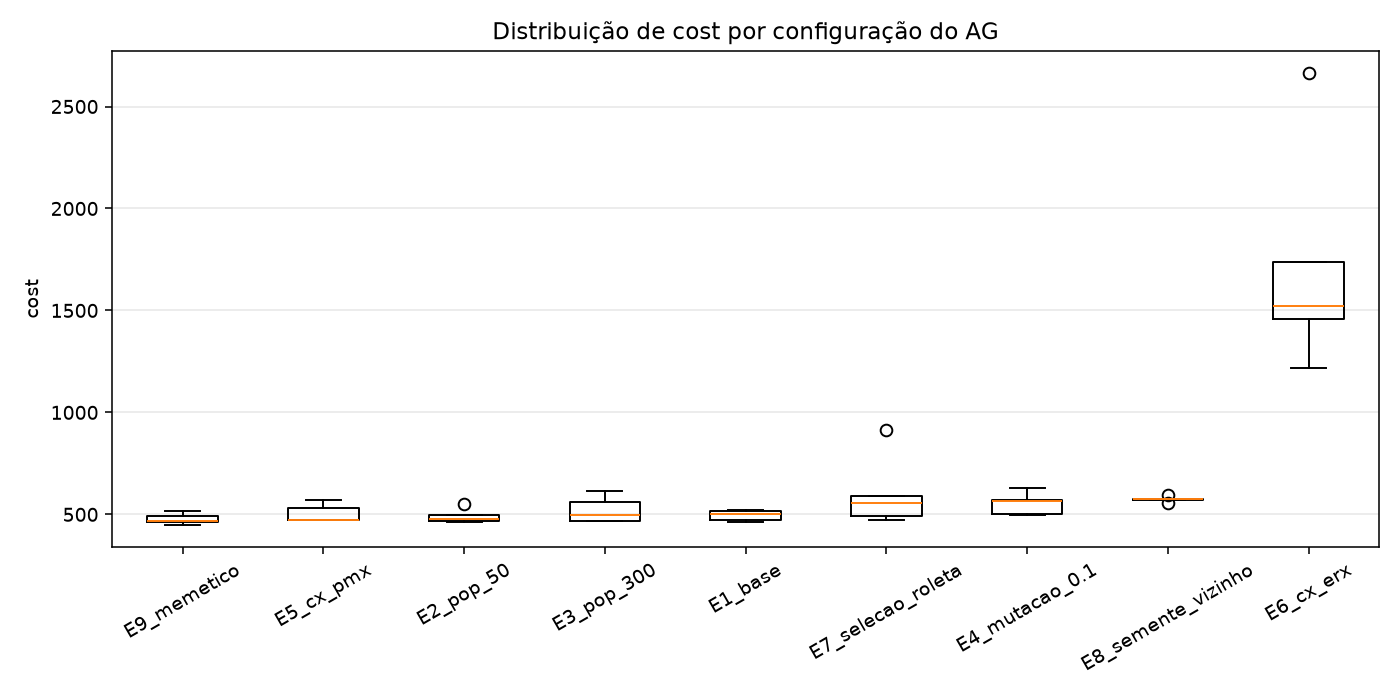

In [7]:
display(Image(RES / 'convergence.png'))
display(Image(RES / 'boxplot_cost.png'))

## 4. Comparativo com outras abordagens

In [8]:
pd.read_csv(RES / 'methods_comparison.csv')[['metodo','custo_objetivo','distancia_total_km','viavel','tempo_medio_ate_criticas_h','veiculos_usados','tempo_s']]

,metodo,custo_objetivo,distancia_total_km,viavel,tempo_medio_ate_criticas_h,veiculos_usados,tempo_s
0,OR-Tools (GLS 30s),449.13,264.58,True,2.20,4,30.01
1,AG — E9_memetico (melhor de 5 seeds),449.62,264.08,True,2.17,4,21.78
2,AG — E1_base (melhor seed),463.81,273.72,True,2.31,3,15.37
3,Clarke-Wright (savings),979.14,314.14,False,3.14,4,0.01
4,Vizinho mais próximo,1659.72,371.60,False,4.67,3,0.00
5,Aleatório (melhor de 2000),15994.72,630.62,False,5.43,5,0.07
6,"Código base (TSP, 1 veículo)",87668.80,311.13,False,13.91,1,6.58


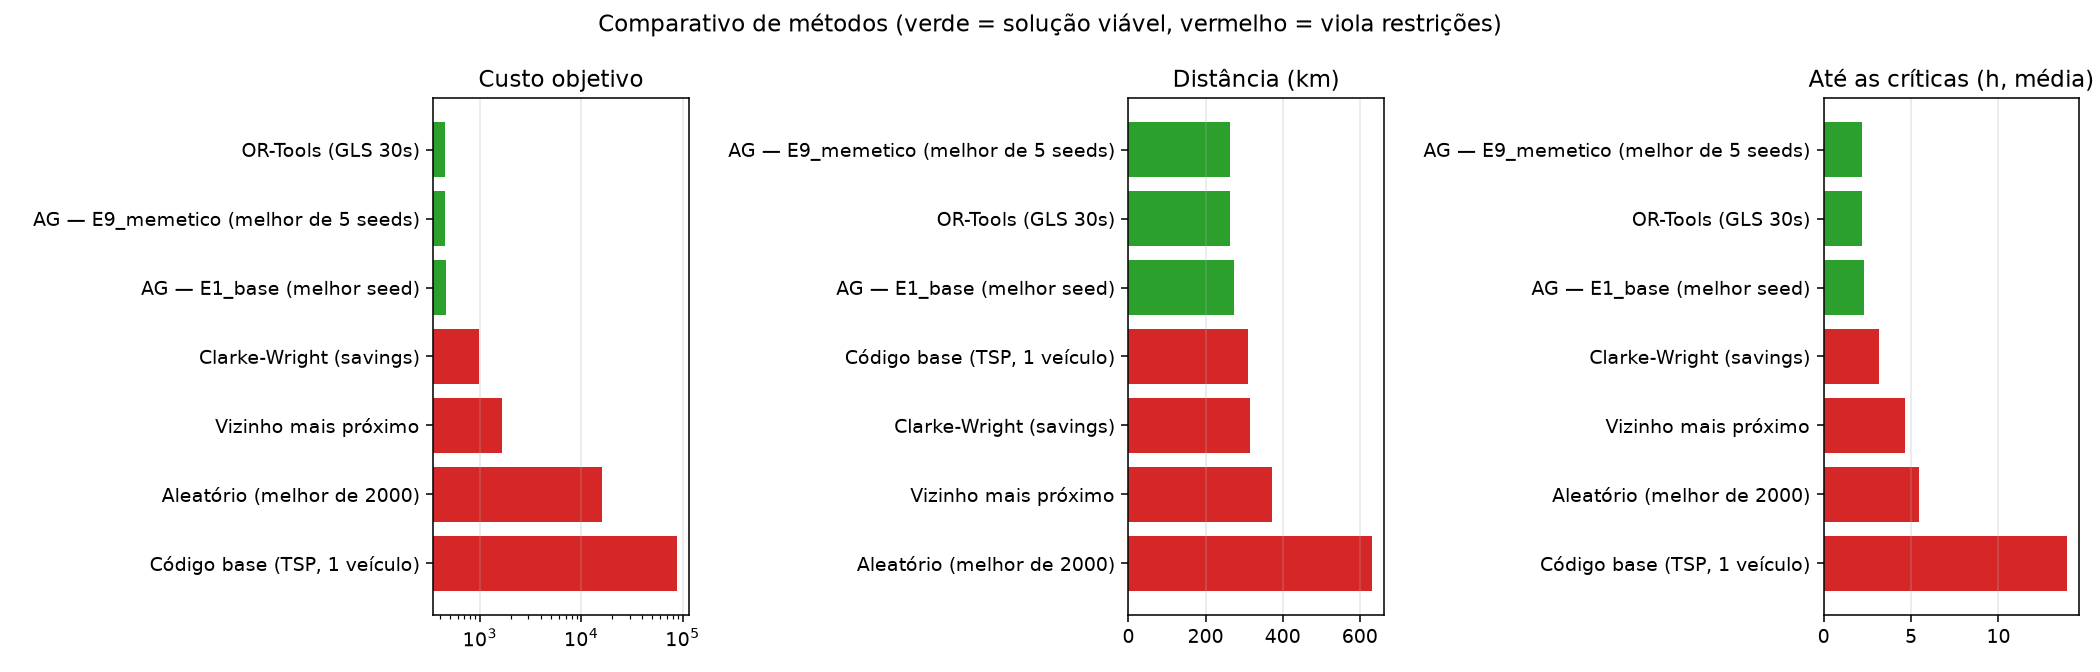

entregas,20,40,80
metodo,,,
AG memético,296.5,826.3,915.0
Clarke-Wright,402.2,1354.8,3364.7
OR-Tools (30s),296.5,3919.3,1560.0
Vizinho mais próximo,670.9,2081.3,3267.0


In [9]:
display(Image(RES / 'methods_comparison.png'))
if (RES / 'scalability.csv').exists():
    display(pd.read_csv(RES / 'scalability.csv').pivot(index='metodo', columns='entregas', values='custo'))

## 5. Mapa da melhor solução

In [10]:
from rotas.solution import Solution
from rotas.viz.maps import route_map
best = Solution.load(RES / 'best_solution.json')
route_map(best)

## 6. Semana simulada (AG × método anterior)

In [11]:
week = json.loads((RES / 'weekly_history.json').read_text())
pd.Series(week['totais'])

dias                                       7.00
entregas                                 284.00
entregas_criticas                         62.00
entregas_refrigeradas                     75.00
km_otimizado                            2144.80
km_metodo_anterior                      2837.00
economia_km                              692.20
economia_km_pct                           24.40
custo_otimizado_rs                      3286.75
custo_metodo_anterior_rs                4085.48
economia_rs                              798.73
horas_conducao_otimizado                  93.30
horas_conducao_anterior                  120.70
economia_horas                            27.40
dias_viaveis_otimizado                     7.00
dias_viaveis_anterior                      2.00
tempo_medio_ate_criticas_h_otimizado       1.79
tempo_medio_ate_criticas_h_anterior        4.72
dtype: float64

## 7. LLM — textos gerados pelo Gemini

In [12]:
display(Markdown((RES / 'llm' / 'instrucoes_van_refrigerada_2_v1.md').read_text()))

## Resumo da rota
- Veículo: Van Refrigerada 2
- Horário de saída: 08:00
- Retorno previsto: 16:12
- Distância total: 118.66 km
- Carga total: 326.9 kg
- Número de paradas: 15 (sendo 3 críticas e 7 refrigeradas)

## Antes de sair
- Confira o carregamento. Carregue na ordem INVERSA das entregas (a última entrega vai ao fundo do veículo).
- Como há itens refrigerados, confira a temperatura (2 °C a 8 °C).

## Paradas
**1. UBS Jabaquara 01** (Jabaquara) — chegada prevista 08:32
- Entregar: 30.7 kg — Antibióticos de amplo espectro, Material de higiene, Seringas e agulhas
- 🔴 CRÍTICA
- Conferir itens com o responsável da unidade e colher assinatura.

**2. UBS Ipiranga 01** (Ipiranga) — chegada prevista 09:05
- Entregar: 42.4 kg — Gaze e curativos, Material de higiene
- Conferir itens com o responsável da unidade e colher assinatura.

**3. Paciente domiciliar #32 (Vila Prudente)** (Vila Prudente) — chegada prevista 09:30
- Entregar: 3.6 kg — Insulina
- ❄️ REFRIGERADO · ⏰ janela 08:00-10:00
- Conferir itens com o responsável da unidade e colher assinatura.

**4. Paciente domiciliar #27 (São Mateus)** (São Mateus) — chegada prevista 10:12
- Entregar: 2.2 kg — Imunobiológicos
- ❄️ REFRIGERADO · ⏰ janela 09:30-11:30
- Conferir itens com o responsável da unidade e colher assinatura.

**5. Hospital Dia Tatuapé 01** (Tatuapé) — chegada prevista 11:03
- Entregar: 100.0 kg — Soro fisiológico, Seringas e agulhas
- Conferir itens com o responsável da unidade e colher assinatura.

**6. Paciente domiciliar #02 (Tatuapé)** (Tatuapé) — chegada prevista 11:19
- Entregar: 4.2 kg — Insulina, Material de higiene
- ❄️ REFRIGERADO · ⏰ janela 08:30-11:30
- Conferir itens com o responsável da unidade e colher assinatura.

**7. Clínica de Especialidades Penha 01** (Penha) — chegada prevista 11:41
- Entregar: 7.4 kg — Material de higiene
- Conferir itens com o responsável da unidade e colher assinatura.

**8. Paciente domiciliar #14 (Penha)** (Penha) — chegada prevista 11:50
- Entregar: 3.5 kg — Soro fisiológico, Luvas e EPIs
- ⏰ janela 10:30-12:30
- Conferir itens com o responsável da unidade e colher assinatura.

**9. Paciente domiciliar #37 (Penha)** (Penha) — chegada prevista 12:04
- Entregar: 4.5 kg — Imunobiológicos
- ❄️ REFRIGERADO · ⏰ janela 12:00-14:00
- Conferir itens com o responsável da unidade e colher assinatura.

**10. Clínica de Especialidades São Miguel Paulista 01** (São Miguel Paulista) — chegada prevista 12:55
- Entregar: 20.0 kg — Anticoagulantes, Analgésicos, Luvas e EPIs
- 🔴 CRÍTICA
- Conferir itens com o responsável da unidade e colher assinatura.

**11. Paciente domiciliar #38 (São Miguel Paulista)** (São Miguel Paulista) — chegada prevista 13:08
- Entregar: 5.0 kg — Insulina, Material de higiene
- ❄️ REFRIGERADO · ⏰ janela 12:00-15:00
- Conferir itens com o responsável da unidade e colher assinatura.

**12. Paciente domiciliar #22 (Guaianases)** (Guaianases) — chegada prevista 13:41
- Entregar: 2.6 kg — Insulina, Anticoagulantes, Analgésicos
- 🔴 CRÍTICA · ❄️ REFRIGERADO · ⏰ janela 13:00-15:00
- Conferir itens com o responsável da unidade e colher assinatura.

**13. Clínica de Especialidades Guaianases 01** (Guaianases) — chegada prevista 13:59
- Entregar: 17.3 kg — Luvas e EPIs, Seringas e agulhas
- Conferir itens com o responsável da unidade e colher assinatura.

**14. Hospital Dia Itaquera 01** (Itaquera) — chegada prevista 14:21
- Entregar: 68.4 kg — Soro fisiológico, Material de higiene
- Conferir itens com o responsável da unidade e colher assinatura.

**15. UBS Vila Prudente 01** (Vila Prudente) — chegada prevista 15:29
- Entregar: 15.1 kg — Insulina, Luvas e EPIs, Seringas e agulhas
- ❄️ REFRIGERADO
- Conferir itens com o responsável da unidade e colher assinatura.

## Atenção
- Janelas apertadas.
- Uso alto da capacidade e da autonomia.

## Em caso de imprevisto
- Avisar a Central.
- Priorizar entregas críticas e refrigeradas.
- Nunca deixar refrigerados fora da caixa térmica.

In [13]:
display(Markdown((RES / 'llm' / 'relatorio_semanal.md').read_text()))

**Relatório Semanal de Eficiência de Rotas**  
**Destinatário:** Diretoria do Hospital Universitário  
**Emitente:** Assistência de Logística da Central de Distribuição Farmacêutica  
**Período de Análise:** 2026-10-05 a 2026-10-11  

---

## Resumo da semana

*   **Volume de Operação:** Realização de **284 entregas** ao longo de 7 dias de operação contínua.
*   **Garantia de Fluxo Crítico e Cadeia Fria:** Foram distribuídas **62 entregas de prioridade crítica (como quimioterápicos e drogas de UTI)** e **75 entregas refrigeradas (cadeia fria de 2 °C a 8 °C)**, assegurando o abastecimento essencial de unidades de saúde e pacientes domiciliares.
*   **Viabilidade Operacional:** O método otimizado garantiu **100% de viabilidade das rotas** (7 dias viáveis), enquanto o método anterior apresentaria viabilidade em apenas 2 dias do período.
*   **Agilidade no Atendimento Crítico:** O tempo médio para a entrega de insumos críticos foi reduzido de 4.72 horas (método anterior) para **1.79 horas** com o sistema otimizado.

---

## Economia gerada pela otimização

A transição para o sistema de rotas otimizadas gerou reduções expressivas no consumo de recursos logísticos em comparação ao método anterior:

*   **Redução de Quilometragem:** Economia direta de **692.2 km** (redução de 24.4%), reduzindo a distância total percorrida de 2837.0 km para 2144.8 km.
*   **Redução de Custos Financeiros:** O custo total de transporte caiu de R$ 4085.48 para R$ 3286.75, gerando uma **economia líquida de R$ 798.73** na semana.
*   **Eficiência em Horas de Condução:** Redução de **27.4 horas** de tempo de direção dos motoristas (de 120.7 horas para 93.3 horas), otimizando a jornada de trabalho da equipe.

---

## Evolução diária

A tabela abaixo detalha o comportamento da operação e os ganhos diários obtidos com a otimização de rotas:

| Dia da Semana | Data | Entregas | Km Otimizado | Km Anterior | Economia % | Tempo Médio até Críticas (h) |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: |
| Segunda-feira | 2026-10-05 | 35 | 280.92 | 330.78 | 15.1% | 1.54 |
| Terça-feira | 2026-10-06 | 47 | 388.62 | 477.10 | 18.5% | 1.78 |
| Quarta-feira | 2026-10-07 | 42 | 365.50 | 498.69 | 26.7% | 2.78 |
| Quinta-feira | 2026-10-08 | 37 | 268.24 | 470.62 | 43.0% | 1.29 |
| Sexta-feira | 2026-10-09 | 44 | 294.04 | 390.18 | 24.6% | 0.86 |
| Sábado | 2026-10-10 | 39 | 256.91 | 344.03 | 25.3% | 2.29 |
| Domingo | 2026-10-11 | 40 | 290.58 | 325.59 | 10.8% | 2.00 |

---

## Qualidade do serviço

*   **Atendimento de Itens Críticos:** As **62 entregas críticas** (quimioterápicos e drogas de UTI) foram priorizadas, atingindo o tempo médio de entrega de 1.79 horas. O dia de maior agilidade foi a sexta-feira, com média de 0.86 horas (51.6 minutos) para o recebimento destes insumos.
*   **Segurança da Cadeia Fria (2 °C a 8 °C):** As **75 entregas refrigeradas** foram distribuídas utilizando veículos especializados. A Van Refrigerada 1 operou com 78.1% de ocupação média e a Van Refrigerada 2 com 77.3% de ocupação. Ambos os veículos trabalharam durante todos os 7 dias da semana (0 dias sem uso), garantindo a integridade térmica dos medicamentos.
*   **Violações de Restrições e Atrasos:** Não consta nos dados o registro de atrasos por bairro ou violações de restrições de entrega para o período analisado.

---

## Recomendações

1.  **Redimensionamento e Ajuste de Frota de Apoio:** Avaliar a escala e a necessidade das motocicletas na operação. Enquanto as vans refrigeradas operaram sem folga (0 dias sem uso) e com alta ocupação, a Moto 4 ficou sem uso por 4 dias (ocupação média de 37.3%) e a Moto 5 ficou sem uso por 3 dias (ocupação média de 43.8%).
2.  **Ajuste de Planejamento para Dias de Baixa Performance:** Investigar as rotas de domingo, dia que apresentou a menor economia percentual da semana (10.8% de economia de km), visando identificar se há restrições específicas de tráfego ou dispersão geográfica dos pacientes de atendimento domiciliar que justifiquem o índice.
3.  **Reforço Operacional em Dias de Pico:** Manter atenção ao planejamento de escalas de motoristas para as sextas-feiras (identificada como o dia de maior demanda geral) e terças-feiras (dia com o maior volume absoluto de entregas, totalizando 47).

In [14]:
display(Markdown((RES / 'llm' / 'sugestoes.md').read_text()))

Como assistente de logística da Central de Distribuição Farmacêutica, apresento a análise do histórico operacional do período de **2026-10-05 a 2026-10-11**. 

### ⚠️ Destaque de Segurança e Cadeia Fria
Durante esta semana, foram realizadas **284 entregas no total**, das quais:
*   **62 entregas de prioridade crítica** (como quimioterápicos e drogas de UTI).
*   **75 entregas refrigeradas** (itens de cadeia fria, mantidos entre 2 °C a 8 °C).

A garantia da integridade térmica e a agilidade na entrega desses insumos são os pilares mais importantes da nossa operação de apoio à saúde.

Abaixo, apresento as propostas de melhoria estruturadas como hipóteses a serem validadas, ordenadas da maior para a menor relevância para a operação:

---

### 1. Plano de Contingência e Manutenção para Vans Refrigeradas
*   **Evidência nos dados:** A Van Refrigerada 1 apresentou 78,1% de ocupação média, 0 dias sem uso e 508,3 km rodados. A Van Refrigerada 2 registrou 77,3% de ocupação média, 0 dias sem uso e 695,7 km rodados. Ambos os veículos operam no limite de sua capacidade diária para garantir o transporte das 75 entregas refrigeradas (cadeia fria, 2 °C a 8 °C).
*   **Sugestão:** Validar a criação de um cronograma rigoroso de manutenção preventiva escalonada para as Vans Refrigeradas 1 e 2 (garantindo que nunca parem no mesmo dia) e homologar um plano de contingência (como caixas térmicas validadas para uso nas motos ou na Van de Carga) para assegurar o transporte de refrigerados em caso de quebra de um dos veículos.
*   **Impacto esperado:** Mitigação do risco de perda de insumos térmicos por falha mecânica e garantia de continuidade absoluta da cadeia fria.
*   **Como medir:** Dias sem uso por veículo e taxa de ocupação média por veículo.

### 2. Investigação do Gargalo Logístico aos Domingos
*   **Evidência nos dados:** O domingo foi apontado como o "dia_menor_economia", registrando apenas 10,8% de economia de km (35,0 km economizados), apesar de concentrar um volume expressivo de 12 entregas críticas e 15 entregas refrigeradas.
*   **Sugestão:** Investigar as restrições de tráfego, janelas de entrega dos hospitais e endereços dos pacientes atendidos no domingo para entender por que o algoritmo de otimização teve o menor desempenho semanal, buscando flexibilizar restrições não obrigatórias para dar mais vazão às 12 entregas críticas e 15 refrigeradas deste dia.
*   **Impacto esperado:** Aumento da eficiência das rotas de fim de semana, redução do desgaste da frota e maior rapidez na entrega de medicamentos de UTI e quimioterápicos aos domingos.
*   **Como medir:** Economia de km (%) aos domingos e tempo médio até entregas críticas (h).

### 3. Redimensionamento da Carga da Van de Carga 3
*   **Evidência nos dados:** A Van Carga 3 rodou 649,0 km ao longo de 7 dias (0 dias sem uso), porém registrou uma ocupação média de apenas 48,8%.
*   **Sugestão:** Avaliar a viabilidade de consolidar mais entregas de carga seca (não refrigerada) neste veículo ou verificar se parte de suas entregas de menor volume pode ser transferida para as motocicletas nos dias de alta demanda, otimizando o espaço físico da van.
*   **Impacto esperado:** Aumento da eficiência volumétrica do veículo de carga e redução do custo operacional por item entregue.
*   **Como medir:** Ocupação média por veículo (%) da Van Carga 3.

### 4. Otimização da Escala e Redução de Ociosidade das Motocicletas
*   **Evidência nos dados:** A Moto 4 registrou 4 dias sem uso, com ocupação média de 37,3% e 128,2 km rodados. A Moto 5 registrou 3 dias sem uso, com ocupação média de 43,8% e 163,5 km rodados.
*   **Sugestão:** Testar a redistribuição de entregas de pequeno volume e de caráter urgente (não refrigeradas) para as motocicletas, reduzindo os dias de ociosidade desses veículos e aproveitando sua agilidade no trânsito de São Paulo.
*   **Impacto esperado:** Melhor distribuição da carga de trabalho entre a frota leve e redução do tempo de resposta para entregas rápidas de insumos não refrigerados.
*   **Como medir:** Dias sem uso por veículo e ocupação média por veículo (%) das motos 4 e 5.

### Avaliação de qualidade: prompt ingênuo (v0) × prompt elaborado (v1)

In [15]:
ev = pd.read_csv(RES / 'llm_eval.csv')
ev.groupby('prompt')[['geral','fidelidade_numerica','cobertura','destaques','estrutura','palavras']].mean().round(3)

,geral,fidelidade_numerica,cobertura,destaques,estrutura,palavras
prompt,,,,,,
v0,0.824,0.974,0.646,1.0,0.5,548.75
v1,1.000,1.000,1.000,1.0,1.0,458.25


## 8. Chat (uma pergunta ao vivo — consome 1 requisição da cota)

In [16]:
from rotas.llm.assistant import RouteAssistant
asst = RouteAssistant(best, comparison=pd.read_csv(RES / 'methods_comparison.csv'))
chat = asst.start_chat()
print(chat.send('Quais entregas críticas a Van Refrigerada 2 faz e em que horário?'))

Cota diária esgotada para gemini-3.5-flash — tentando o próximo modelo


A **Van Refrigerada 2** realiza 3 entregas críticas:

1. Parada **#1**: **UBS Jabaquara 01**, com chegada prevista para as **08:32**.
2. Parada **#10**: **Clínica de Especialidades São Miguel Paulista 01**, com chegada prevista para as **12:55**.
3. Parada **#12**: **Paciente domiciliar #22 (Guaianases)**, com chegada prevista para as **13:41** (item refrigerado e de alta prioridade).
